<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   str    
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 136.8 KB


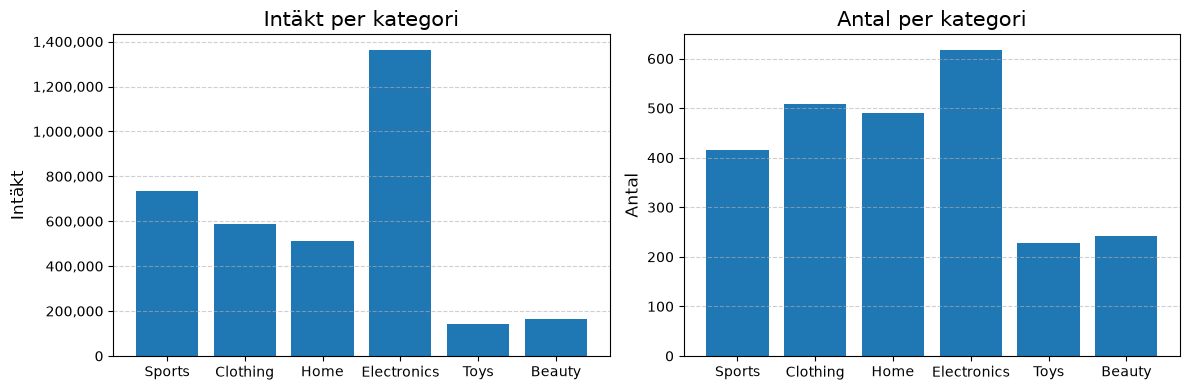

In [1]:
import sys, os

sys.path.append(os.path.abspath(".."))
from src import load_data, EcommerceAnalyzer
from src.viz import (
    plot_category_analysis,
    plot_revenue_by_category,
    plot_revenue_by_city,
    plot_monthly_revenue
    )

import pandas as pd

# Hämtar in data med load_data
data = load_data("../Data/ecommerce_sales.csv")

# Omvandlar data till en dataframe
df = pd.DataFrame(data)

# Kontrollerar värdena i dataframen
df.info()

# Hämtar in analyserna från EcommerceAnalyser
analysis = EcommerceAnalyzer(data)


# Category analysis
category_counts, revenue_per_category = analysis.category_analysis()
plot_category_analysis(category_counts, revenue_per_category)

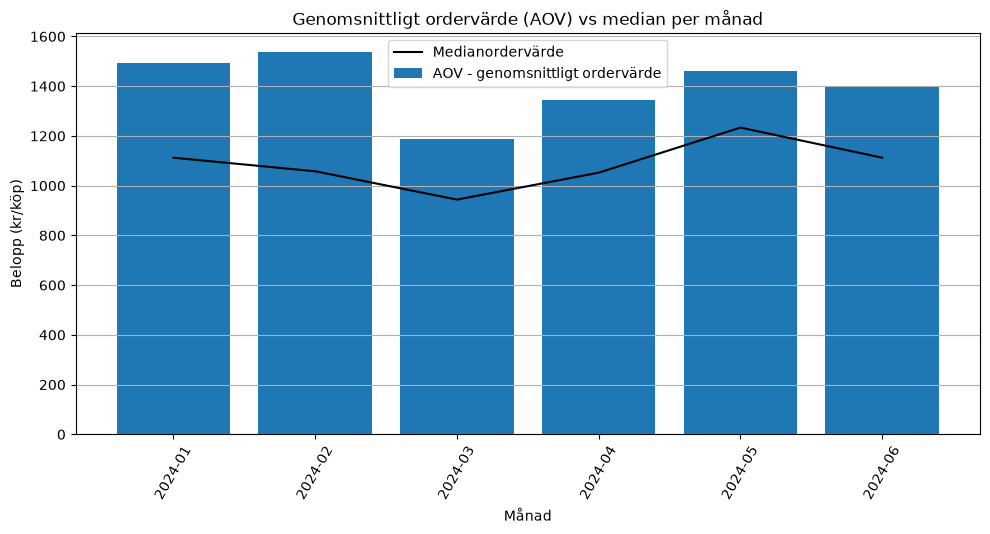

AOV för de första sex månaderna 2024 är: 1401 kr.
Medianen för de första sex månaderna 2024 är: 1089 kr.


In [2]:
import matplotlib.pyplot as plt
from src import viz as v
from src import metrics as M

# Ändrar på formatet på kolumnen "date" i dataframen. Frå sträng till datumsformat.
df["date"] = pd.to_datetime(df["date"])
# Grupperar datan i kolumnen "revenue" per månad och räknar ut medel (AOV) och median för varje månad.
monthly_stats = df.groupby(df["date"].dt.to_period("M"))["revenue"].agg(
    ["mean", 
     "median"])

# Formen för diagrammet initieras
fig, ax = plt.subplots(figsize=(10, 5))
# Skickar datan till funktionen som ska rita diagrammen
v.plot_monthly_data(ax, monthly_stats)

plt.show()

# Här presenteras resultatet för aov och median för hela datamängden.
print(f"AOV för de första sex månaderna 2024 är: {M.average_order_value(data):.0f} kr.")
print(f"Medianen för de första sex månaderna 2024 är: {M.calc_median(data):.0f} kr.")

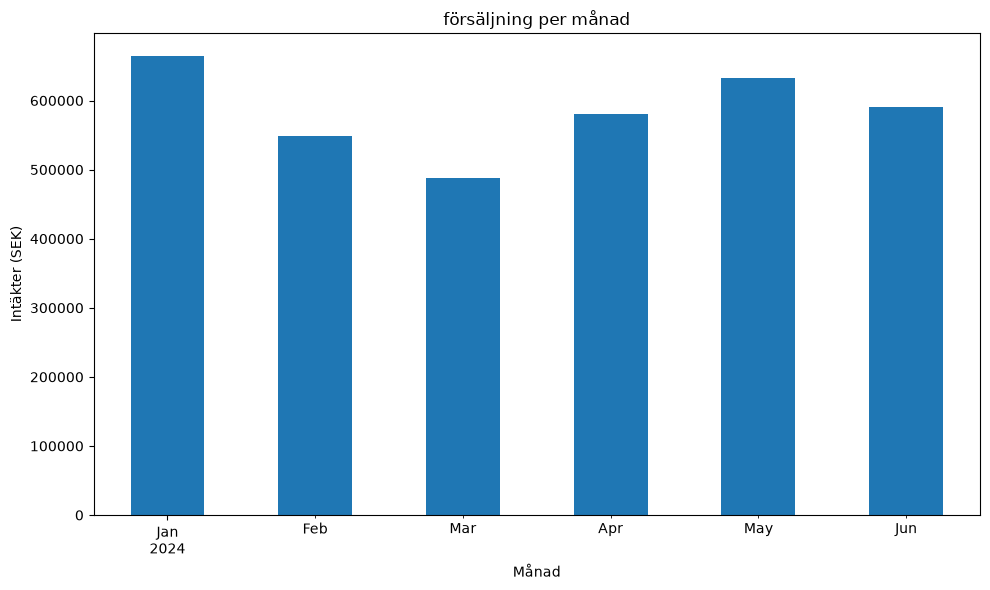

In [3]:
fig, ax = plot_monthly_revenue(data)
plt.show()

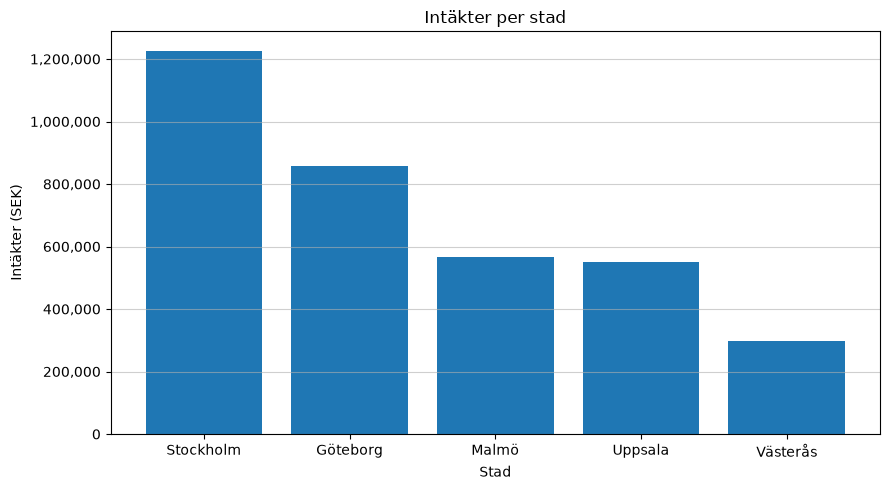

In [4]:
city_revenue = analysis.revenue_by_city()
fig, ax = plot_revenue_by_city(city_revenue)
plt.show()

# Intäkt per stad

Figuren visar vilken stad som säljer bäst under den studerade tiden. Stockholm är bäst med ca 400.000 SEK

## Top 3 Categories by Revenue

This chart shows the three product categories that generated the most revenue during the observed period. It helps identify which categories contribute most to sales.

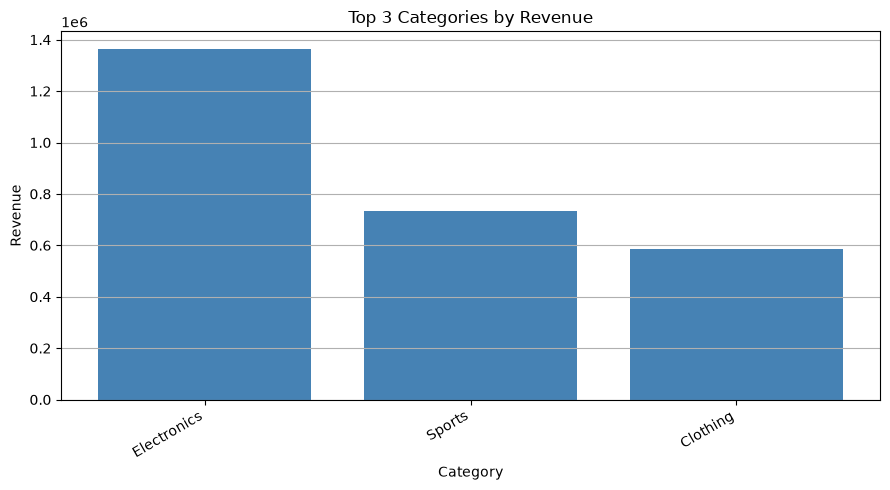

In [13]:
# Import the function that plots the top three categories by revenue
from src.viz import plot_revenue_by_category
import matplotlib.pyplot as plt

# Find the three categories with the highest total revenue
top_category_revenue = analysis.top_categories()

# Create and display the chart
plot_revenue_by_category(top_category_revenue)
plt.show()